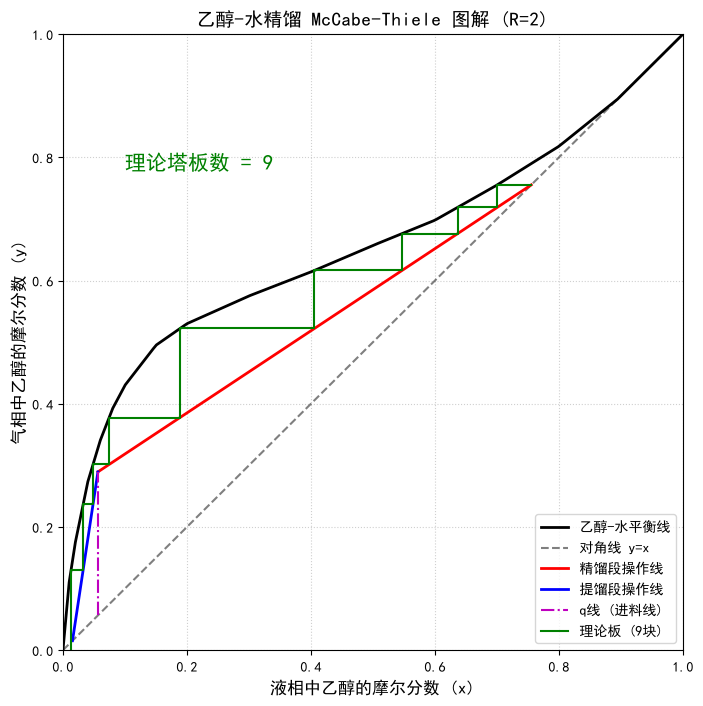

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# 设定中文
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 1. 参数设定 =================
# 使用我们刚才算出来的乙醇-水数据
xF = 0.0564     # 进料摩尔分数
xD = 0.7554     # 塔顶摩尔分数
xW = 0.0154     # 塔底摩尔分数
R = 2           # 回流比

# ================= 2. 乙醇-水真实相平衡数据（常压） =================
# 因为乙醇-水有共沸点，不能用固定alpha，这里用查表数据插值
x_data = np.array([0, 0.01, 0.02, 0.04, 0.06, 0.08, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.894, 1.0])
y_data = np.array([0, 0.11, 0.175, 0.273, 0.34, 0.392, 0.43, 0.495, 0.53, 0.575, 0.614, 0.657, 0.698, 0.755, 0.818, 0.894, 1.0])

# 创建插值函数，方便后面用 y 反求 x（画阶梯用）
f_y2x = interp1d(y_data, x_data, kind='linear', fill_value="extrapolate")
f_x2y = interp1d(x_data, y_data, kind='linear', fill_value="extrapolate")

# 生成画平衡线的坐标
x_curve = np.linspace(0, 1, 200)
y_curve = f_x2y(x_curve)

# ================= 3. 操作线方程 =================
# 精馏段操作线
slope_rect = R / (R + 1)
intercept_rect = xD / (R + 1)

# 提馏段操作线（泡点进料，交点 q 线）
x_q = xF 
y_q = slope_rect * x_q + intercept_rect

slope_strip = (y_q - xW) / (x_q - xW)
intercept_strip = xW - slope_strip * xW

# ================= 4. 绘制基础图形 =================
fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(x_curve, y_curve, 'k-', linewidth=2, label='乙醇-水平衡线')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='对角线 y=x')

# 注意：操作线不能画全图，只在特定区间画
x_rect_plot = np.linspace(xF, xD, 10)
ax.plot(x_rect_plot, slope_rect * x_rect_plot + intercept_rect, 'r-', linewidth=2, label='精馏段操作线')

x_strip_plot = np.linspace(xW, xF, 10)
ax.plot(x_strip_plot, slope_strip * x_strip_plot + intercept_strip, 'b-', linewidth=2, label='提馏段操作线')

# 画进料线 (q线)
ax.plot([xF, xF], [xF, y_q], 'm-.', linewidth=1.5, label='q线 (进料线)')

# ================= 5. 画阶梯 =================
x_curr = xD
y_curr = xD
stage = 0

# 记录阶梯坐标点以便画图
x_steps = [x_curr]
y_steps = [y_curr]

while x_curr > xW:
    stage += 1
    
    # 1. 水平向左走：从当前 y 找到平衡线上的 x
    x_eq = f_y2x(y_curr)
    x_steps.append(x_eq)
    y_steps.append(y_curr)
    
    # 2. 垂直向下走：找操作线上的 y_next
    if x_eq > xF:
        y_next = slope_rect * x_eq + intercept_rect
    else:
        y_next = slope_strip * x_eq + intercept_strip
        
    x_steps.append(x_eq)
    y_steps.append(y_next)
    
    # 更新坐标
    x_curr = x_eq
    y_curr = y_next

    if stage > 100:
        print("警告：塔板数超过100，发生死循环。")
        break

# 画出所有阶梯
ax.plot(x_steps, y_steps, 'g-', linewidth=1.5, label=f'理论板 ({stage}块)')

# ================= 6. 图形美化 =================
ax.text(0.1, 0.78, f'理论塔板数 = {stage}', fontsize=15, color='green', fontweight='bold')

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('液相中乙醇的摩尔分数 (x)', fontsize=12)
ax.set_ylabel('气相中乙醇的摩尔分数 (y)', fontsize=12)
ax.set_title('乙醇-水精馏 McCabe-Thiele 图解 (R=2)', fontsize=14)
ax.legend(loc='lower right')
ax.grid(True, linestyle=':', alpha=0.6)

plt.show()